### Javier Carballal Morgade
### Claudia Reyero Bardelás

# Deutsch-Jozsa algorithm.

The Deutsch-Jozsa algorithm determines if an $f$ given is either *constant* (gives the same output for every input) or *balanced* (gives and output of `0`for half of the inputs and an output of `1` for the other half).

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from itertools import product

## Generate the deutsch jozsa function

First we create the function that executes the circuit algorithm, it uses as inputs the function to be predicted as constant or balanced and the number of qubits.

In [2]:
def deutsch_jozsa_run(f, n):
    # Create circuit
    circuit = QuantumCircuit(n + 1, n)
    # Initialize the ancilla as |1>
    circuit.x(n)
    # Apply H to all the qubits
    for i in range(n + 1):
        circuit.h(i)
    circuit.barrier()
    # Apply the oracle function
    f(circuit, n)         
    circuit.barrier()
    # Apply H to all the qubits except the ancilla
    for i in range(n):
        circuit.h(i)
    # Measure all the quits except the ancilla
    for i in range(n):
        circuit.measure(i, i)
    return circuit

## Constant function

Now we create the constant function to test the algorithm. In this case, we used a function that applies ones to all of the qubits.

In [3]:
def constant_function(circuit, n):
    circuit.x(n)

We create the circuit of the algorithm for this constant function and we print its aspect.

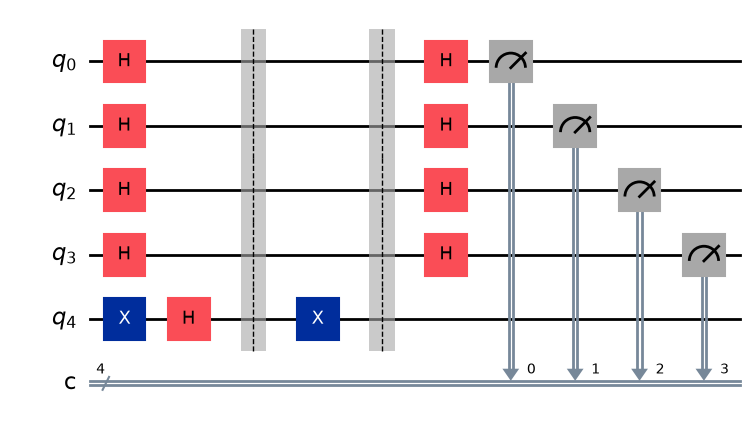

In [4]:
n = 4
qc_constant = deutsch_jozsa_run(constant_function, n)
qc_constant.draw("mpl")

We run the circuit on the simulator and analize the result.

Constant function results: {'0000': 1024}


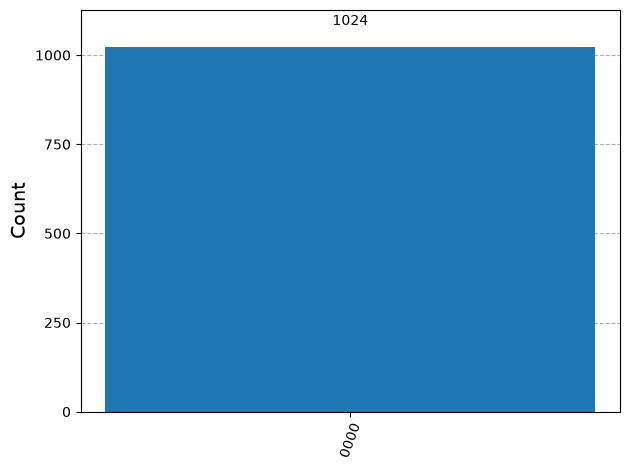

In [5]:
# Conect to the simulador
sim = AerSimulator()
# Transpile the circuit
compiled_cons = transpile(qc_constant, sim)
# Run the simulation
result_cons = sim.run(compiled_cons).result()
# Count the results
counts_cons = result_cons.get_counts()
# Print the results
print("Constant function results:", counts_cons)
plot_histogram(counts_cons)

We can see that the result is 0000 with a probability of 1, this demonstrates that the function is constant.

## Balanced function

Now we create the balanced function to test the algorithm. In this case, we used a function that applies CNOT to the first two qubtis.

In [6]:
def balanced_function(circuit, n):
    circuit.cx(0, n)
    circuit.cx(1, n)

We create the circuit of the algorithm for this balanced function and we print its aspect.

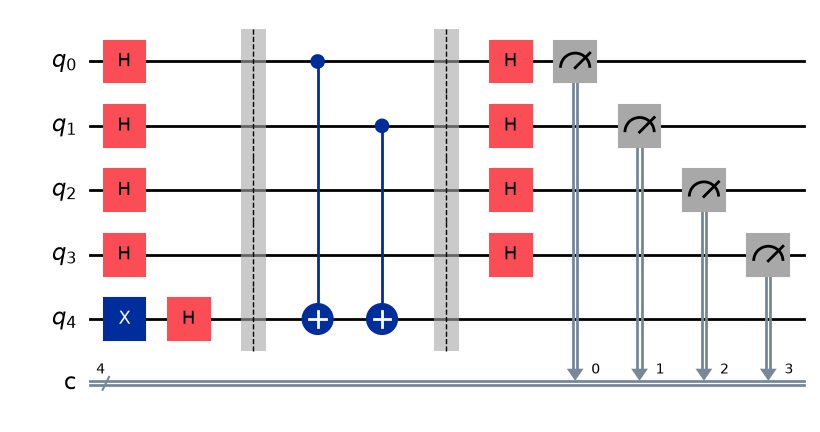

In [7]:
n = 4
qc_balanced = deutsch_jozsa_run(balanced_function, n)
qc_balanced.draw("mpl")

We run the circuit on the simulator and analize the result.

Balanced function results: {'0011': 1024}


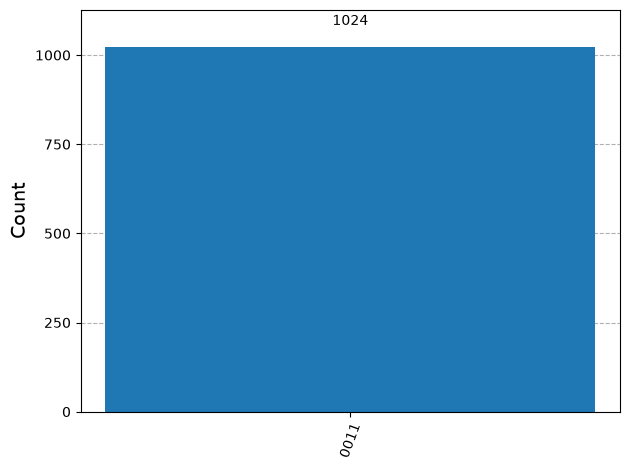

In [8]:
# Transpile the circuit
compiled_bal = transpile(qc_balanced, sim)
# Run the simulation
result_bal = sim.run(compiled_bal).result()
# Count the results
counts_bal = result_bal.get_counts()
# Print the results
print("Balanced function results:", counts_bal)
plot_histogram(counts_bal)

We can see that the result is 0011 with probability 1, this demonstrates that the function is balanced.